# SWAN-SF Whole-Sequence LSTM

In [2]:
# Configure paths, random seed, and core hyperparameters
from pathlib import Path
import numpy as np
import random
import sys, os

sys.path.append(os.path.abspath("../scripts"))

from data_utils import find_project_root
from preprocessing import compute_feature_stats, normalize_sequence_data
from metrics import compute_metrics, sweep_thresholds, format_metrics
from losses import FocalLoss

PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data" / "Cleaned SWANSF Dataset"
print("Project root:", PROJECT_ROOT)
print("Data dir:", DATA_DIR)


random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)


SELECTED_FEATURES = ("SAVNCPP", "ABSNJZH", "R_VALUE", "EPSZ", "TOTFZ")

BATCH_SIZE = 32
NUM_EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.2
EARLY_STOP_PATIENCE = 4
THRESHOLD_GRID = np.linspace(0.1, 0.9, 33)
MAX_ACCEPTABLE_FPR = 0.10

Project root: /Users/chintan/Drive/Projects/solar-flare-classification
Data dir: /Users/chintan/Drive/Projects/solar-flare-classification/data/Cleaned SWANSF Dataset


In [3]:
# Load SWAN-SF partitions (reuse existing preprocessing) and normalize features
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from data_utils import load_sequence_data

X_train_all, y_train_all, X_val_all, y_val_all, X_test_all, y_test_all = load_sequence_data(
    DATA_DIR,
    SELECTED_FEATURES,
    )

print("Train shape:", X_train_all.shape)
print("Validation shape:", X_val_all.shape)
print("Test shape:", X_test_all.shape)

feature_mean, feature_std = compute_feature_stats(X_train_all)

X_train_all = normalize_sequence_data(X_train_all, feature_mean, feature_std)
X_val_all = normalize_sequence_data(X_val_all, feature_mean, feature_std)
X_test_all = normalize_sequence_data(X_test_all, feature_mean, feature_std)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)
print("Num selected attributes:", len(SELECTED_FEATURES))

Train shape: (77865, 60, 5)
Validation shape: (19899, 60, 5)
Test shape: (331185, 60, 5)
Using device: mps
Num selected attributes: 5


In [4]:
# Dataset and dataloaders for full sequences
class SequenceDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = X
        self.y = y.astype(np.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        seq = torch.from_numpy(self.X[idx])
        label = torch.tensor(self.y[idx])
        return seq, label


def pad_collate(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([seq.shape[0] for seq in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True)
    labels = torch.stack(labels)
    return padded, labels, lengths


train_dataset = SequenceDataset(X_train_all, y_train_all)
val_dataset = SequenceDataset(X_val_all, y_val_all)
test_dataset = SequenceDataset(X_test_all, y_test_all)


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=pad_collate)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=pad_collate)


pos_count = float((y_train_all == 1).sum())
neg_count = float((y_train_all == 0).sum())
pos_weight_value = neg_count / pos_count if pos_count > 0 else 1.0
print(f"Train samples: {len(train_dataset)} | pos={int(pos_count)} | neg={int(neg_count)} | pos_weight={pos_weight_value:.2f}")

Train samples: 77865 | pos=37873 | neg=39992 | pos_weight=1.06


In [5]:
# Sequence LSTM, training loop, and evaluation helpers
class SequenceLSTM(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, num_layers: int, dropout: float):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)
        return self.fc(self.dropout(h_n[-1])).squeeze(1)


model = SequenceLSTM(len(SELECTED_FEATURES), HIDDEN_SIZE, NUM_LAYERS, DROPOUT).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight_value,  device=device, dtype=torch.float32))
#criterion = FocalLoss(alpha=0.75, gamma=2.0)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)


def train_one_epoch():
    model.train()
    total = 0.0
    for seqs, labels, lengths in train_loader:
        seqs, labels, lengths = seqs.to(device), labels.to(device), lengths.to(device)
        optimizer.zero_grad()
        loss = criterion(model(seqs, lengths), labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        total += loss.item() * seqs.size(0)
    return total / len(train_loader.dataset)


def predict_scores(loader):
    model.eval()
    labels, scores = [], []
    with torch.no_grad():
        for seqs, batch_labels, lengths in loader:
            seqs, lengths = seqs.to(device), lengths.to(device)
            logits = model(seqs, lengths)
            scores.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(batch_labels.numpy())
    return np.concatenate(labels), np.concatenate(scores)

In [6]:
# Fit model with validation monitoring
best_state = None
best_val = {"tss": -np.inf}
best_threshold = 0.5
epochs_without_gain = 0
for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = train_one_epoch()
    val_labels, val_scores = predict_scores(val_loader)
    val_best, _ = sweep_thresholds(
        val_labels,
        val_scores,
        thresholds=THRESHOLD_GRID,
        max_fpr=MAX_ACCEPTABLE_FPR,
    )
    if val_best["tss"] > best_val["tss"] + 1e-4:
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        best_val = val_best
        best_threshold = val_best["threshold"]
        epochs_without_gain = 0
    else:
        epochs_without_gain += 1
    scheduler.step(val_best["tss"])
    print(f"Epoch {epoch:02d} | loss={train_loss:.4f} | val_tss={val_best['tss']:.3f} | thr={val_best['threshold']:.2f} | val_fpr={val_best['fpr']:.3f}")
    if epochs_without_gain >= EARLY_STOP_PATIENCE:
        print("Early stopping triggered.")
        break

if best_state is not None:
    model.load_state_dict(best_state)
print("Best validation metrics:", format_metrics(best_val, decimals=4))

Epoch 01 | loss=0.1538 | val_tss=0.925 | thr=0.50 | val_fpr=0.052
Epoch 02 | loss=0.1299 | val_tss=0.932 | thr=0.45 | val_fpr=0.044
Epoch 03 | loss=0.1226 | val_tss=0.904 | thr=0.50 | val_fpr=0.044
Epoch 04 | loss=0.1163 | val_tss=0.913 | thr=0.33 | val_fpr=0.047
Epoch 05 | loss=0.1088 | val_tss=0.913 | thr=0.23 | val_fpr=0.053
Epoch 06 | loss=0.1007 | val_tss=0.907 | thr=0.23 | val_fpr=0.048
Early stopping triggered.
Best validation metrics: {'threshold': 0.45, 'roc_auc': 0.9925, 'pr_auc': 0.9915, 'accuracy': 0.966, 'precision': 0.9568, 'recall': 0.9757, 'f1': 0.9661, 'tpr': 0.9757, 'fpr': 0.0436, 'tss': 0.9321, 'hss': 0.932, 'tn': 9563.0, 'fp': 436.0, 'fn': 241.0, 'tp': 9659.0}


In [8]:
# Evaluate on validation/test splits using the best threshold
val_labels_final, val_scores_final = predict_scores(val_loader)
val_metrics = compute_metrics(val_labels_final, val_scores_final, threshold=best_threshold)
test_labels, test_scores = predict_scores(test_loader)
test_metrics = compute_metrics(test_labels, test_scores, threshold=best_threshold)
test_constrained, _ = sweep_thresholds(
    test_labels,
    test_scores,
    thresholds=THRESHOLD_GRID,
    max_fpr=MAX_ACCEPTABLE_FPR,
)

# print("Validation metrics @ threshold:", format_metrics(val_metrics, decimals=4))
# print("Test metrics @ threshold:", format_metrics(test_metrics, decimals=4))
# print("Best test sweep under FPR constraint:", format_metrics(test_constrained, decimals=4))

# Standardized metrics at fixed threshold=0.5 (for cross-notebook consistency)
METRIC_KEYS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'hss', 'tss', 'fpr', 'tpr']
def select_metrics(metrics, keys=METRIC_KEYS):
    return {k: metrics[k] for k in keys if k in metrics}

val_metrics_fixed = compute_metrics(val_labels_final, val_scores_final, threshold=0.5)
test_metrics_fixed = compute_metrics(test_labels, test_scores, threshold=0.5)
# print('Validation metrics @ threshold=0.5:', format_metrics(select_metrics(val_metrics_fixed), decimals=4))
# print('Test metrics @ threshold=0.5:', format_metrics(select_metrics(test_metrics_fixed), decimals=4))


In [9]:
# Present evaluation metrics in table format
import pandas as pd
from IPython.display import display

TABLE_KEYS = [
    "threshold", "accuracy", "precision", "recall", "f1",
    "roc_auc", "pr_auc", "tss", "hss", "fpr", "tpr",
    "tn", "fp", "fn", "tp",
]

def row_for_table(metrics, keys=TABLE_KEYS, decimals=4):
    rounded = format_metrics(metrics, decimals=decimals)
    return {k: rounded[k] for k in keys if k in rounded}

best_threshold_table = pd.DataFrame(
    [
        row_for_table(val_metrics),
        row_for_table(test_metrics),
        row_for_table(test_constrained),
    ],
    index=[
        "Validation @ best threshold",
        "Test @ best threshold",
        "Test best sweep under FPR constraint",
    ],
)

fixed_threshold_table = pd.DataFrame(
    [
        row_for_table({"threshold": 0.5, **select_metrics(val_metrics_fixed)}),
        row_for_table({"threshold": 0.5, **select_metrics(test_metrics_fixed)}),
    ],
    index=[
        "Validation @ threshold=0.5",
        "Test @ threshold=0.5",
    ],
)

print("Evaluation Metrics Table (Best-Threshold and Constrained Results)")
display(best_threshold_table)

print("Evaluation Metrics Table (Fixed Threshold = 0.5)")
display(fixed_threshold_table)

Evaluation Metrics Table (Best-Threshold and Constrained Results)


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tss,hss,fpr,tpr,tn,fp,fn,tp
Validation @ best threshold,0.45,0.9660,0.9568,0.9757,0.9661,0.9925,0.9915,0.9321,0.9320,0.0436,0.9757,9563.0,436.0,241.0,9659.0
Test @ best threshold,0.45,0.8570,0.1117,0.9485,0.1998,0.9617,0.3915,0.8038,0.1720,0.1447,0.9485,277921.0,47030.0,321.0,5913.0
Test best sweep under FPR constraint,0.80,0.9046,0.1487,0.8611,0.2536,0.9617,0.3915,0.7665,0.2288,0.0946,0.8611,294214.0,30737.0,866.0,5368.0


Evaluation Metrics Table (Fixed Threshold = 0.5)


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tss,hss,fpr,tpr
Validation @ threshold=0.5,0.5,0.9634,0.9578,0.9692,0.9635,0.9925,0.9915,0.9269,0.9268,0.0423,0.9692
Test @ threshold=0.5,0.5,0.8618,0.1140,0.9366,0.2033,0.9617,0.3915,0.7970,0.1757,0.1396,0.9366


Whole-Sequence LSTM - Validation


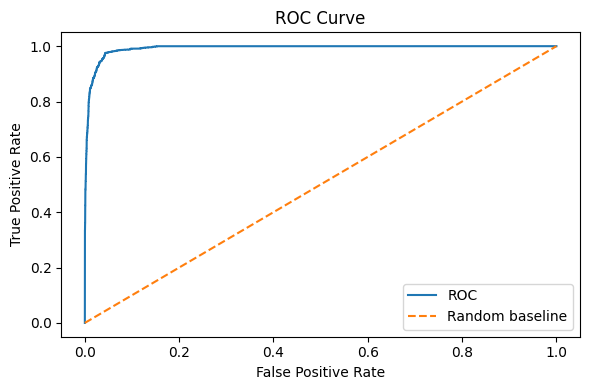

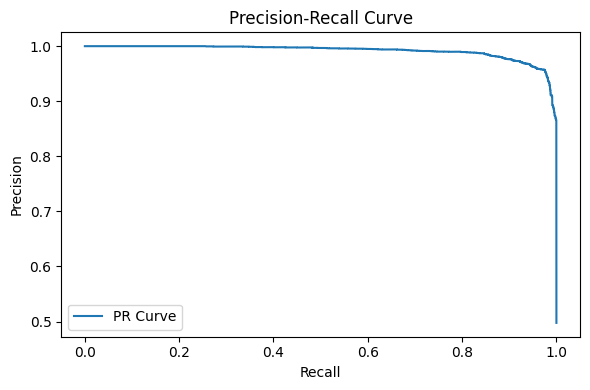

Whole-Sequence LSTM - Test


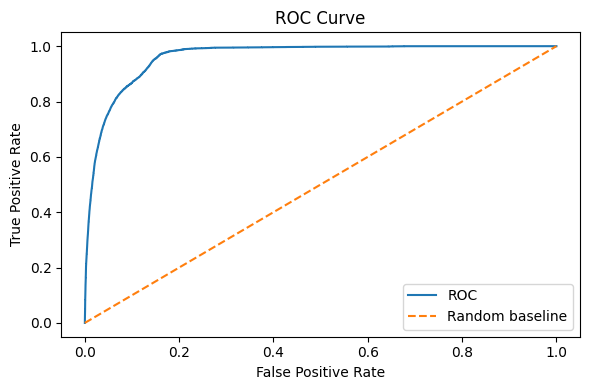

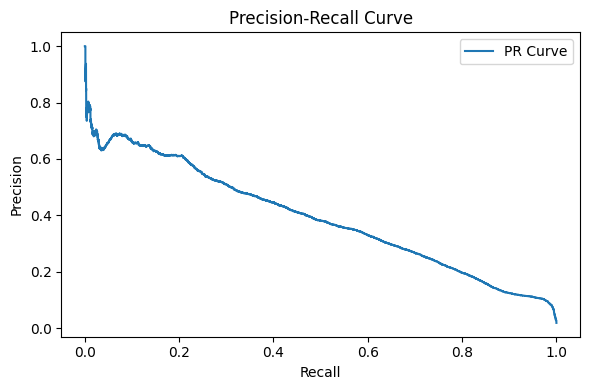

In [10]:
# Plot ROC and PR curves using reusable plotting helpers
from plotting import plot_roc_curve, plot_pr_curve

print("Whole-Sequence LSTM - Validation")
plot_roc_curve(val_labels_final, val_scores_final)
plot_pr_curve(val_labels_final, val_scores_final)

print("Whole-Sequence LSTM - Test")
plot_roc_curve(test_labels, test_scores)
plot_pr_curve(test_labels, test_scores)